# Feature Matching and Image Stitching


In [1]:
# written by HAOLONG ZHENG z5513520
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# get imgs
img1 = cv2.imread('image1.jpg')
img2 = cv2.imread('image2.jpg')

gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# default parameters
sift = cv2.SIFT_create()

kp1 = sift.detect(gray1, None)
kp2 = sift.detect(gray2, None)

img1_kp = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_kp = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

img1_kp = cv2.drawKeypoints(img1_kp, kp1, None)
img2_kp = cv2.drawKeypoints(img2_kp, kp2, None)

In [3]:
sift = cv2.SIFT_create(nfeatures=60)

kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

# brute-force descriptor matcher
bf = cv2.BFMatcher()

# kNN-based matching method
matches = bf.knnMatch(des1, des2, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

result = cv2.drawMatches(img1, kp1, img2, kp2, good_matches, None, matchColor=(0, 0, 255), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

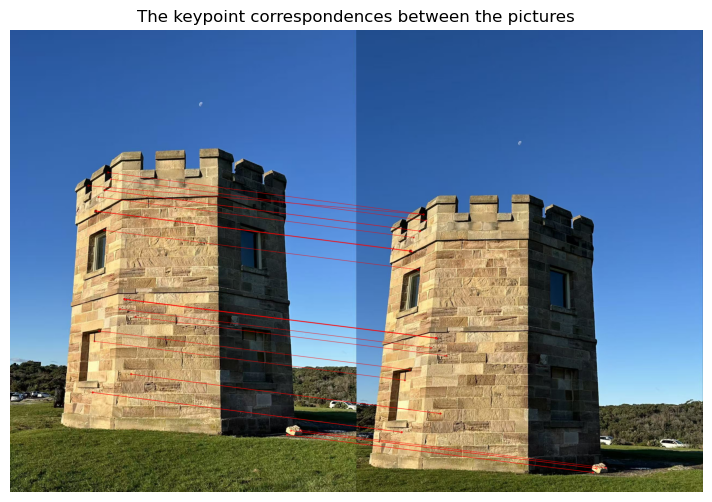

In [4]:
# displays imgs
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("The keypoint correspondences between the pictures")
plt.axis("off")
plt.show()

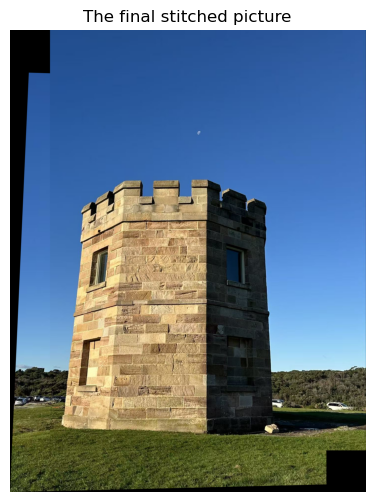

In [5]:
if len(good_matches) > 4:
    # RANSAC algorithm
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    
    corners = np.float32([[0,0], [0,h1], [w1,h1], [w1,0]]).reshape(-1,1,2)
    transformed = cv2.perspectiveTransform(corners, H)
    x_min = np.int32(min(0, transformed[:,0,0].min()))
    y_min = np.int32(min(0, transformed[:,0,1].min()))
    x_max = np.int32(max(w2, transformed[:,0,0].max()))
    y_max = np.int32(max(h2, transformed[:,0,1].max()))
    
    result = cv2.warpPerspective(img1, np.array([[1,0,-x_min],[0,1,-y_min],[0,0,1]]).dot(H), (x_max-x_min, y_max-y_min))
    result[-y_min:-y_min+h2, -x_min:-x_min+w2] = img2

    # displays imgs
    plt.figure(figsize=(12, 6))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title("The final stitched picture")
    plt.axis('off')
    plt.show()
else:
    print("Not enough good matches found to compute homography")